# Logistic Regression – Binary Classification (Adult Income)

**Goal:** predict whether income is `<=50K` or `>50K`, comparing a ready-made sklearn model (LBFGS) with Batch Gradient Descent written from scratch.

**Metrics:** Accuracy, Precision, Recall, F1, Loss (BCE)

---
## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, log_loss, confusion_matrix, classification_report)
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Load & Clean Data

In [2]:
# ===== Load data =====
columns = ['age','workclass','fnlwgt','education','education_num','marital_status',
           'occupation','relationship','race','sex','capital_gain','capital_loss',
           'hours_per_week','native_country','income']

train_path = "/kaggle/input/datasets/johnolafenwa/us-census-data/adult-training.csv"
test_path  = "/kaggle/input/datasets/johnolafenwa/us-census-data/adult-test.csv"

# training file has no header, test file has one junk first line
train_df = pd.read_csv(train_path, names=columns, header=None, skipinitialspace=True)
test_df  = pd.read_csv(test_path,  names=columns, header=0,    skipinitialspace=True)

# clean + encode target
mapping = {'<=50K': 0, '>50K': 1}
for df in [train_df, test_df]:
    df['income'] = df['income'].astype(str).str.strip().str.rstrip('.')
    df['income_encoded'] = df['income'].map(mapping)

print("Train:", train_df.shape, "| Test:", test_df.shape)
print(train_df['income'].value_counts())

Train: (32561, 16) | Test: (16281, 16)
income
<=50K    24720
>50K      7841
Name: count, dtype: int64


## 3. Features / Target & Train–Validation Split

In [3]:
# ===== Features / target + train/validation split =====
feature_columns = columns[:-1]

X = train_df[feature_columns].copy()
y = train_df['income_encoded'].copy()

X_test_original = test_df[feature_columns].copy()
y_test_original = test_df['income_encoded'].copy()

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test_original.shape)

X_train: (26048, 14) | X_val: (6513, 14) | X_test: (16281, 14)


## 4. Preprocessing (Impute → One-Hot → Scale)

In [4]:
# ===== Preprocessing: impute + one-hot + scale =====
numerical_features = ['age','fnlwgt','education_num','capital_gain','capital_loss','hours_per_week']
categorical_features = ['workclass','education','marital_status','occupation',
                        'relationship','race','sex','native_country']

def clean(d):
    d = d.replace('?', np.nan).copy()
    for c in numerical_features:
        d[c] = pd.to_numeric(d[c], errors='coerce')
    for c in categorical_features:
        d[c] = d[c].map(lambda v: np.nan if pd.isna(v) else str(v).strip())
    return d

Xtr, Xva, Xte = clean(X_train), clean(X_val), clean(X_test_original)

num_imp = SimpleImputer(strategy='median')
cat_imp = SimpleImputer(strategy='most_frequent')
enc = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

def build(d, fit=False):
    if fit:
        num = num_imp.fit_transform(d[numerical_features])
        cat = enc.fit_transform(cat_imp.fit_transform(d[categorical_features]))
    else:
        num = num_imp.transform(d[numerical_features])
        cat = enc.transform(cat_imp.transform(d[categorical_features]))
    return np.hstack([num, cat])

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(build(Xtr, fit=True))   # fit on train only
X_val_scaled   = scaler.transform(build(Xva))
X_test_scaled  = scaler.transform(build(Xte))

y_train_np = y_train.to_numpy(dtype=np.float64)
y_val_np   = y_val.to_numpy(dtype=np.float64)
y_test_np  = y_test_original.to_numpy(dtype=np.float64)

print("Train:", X_train_scaled.shape, "| Val:", X_val_scaled.shape, "| Test:", X_test_scaled.shape)

Train: (26048, 105) | Val: (6513, 105) | Test: (16281, 105)


## 5. Logistic Regression – sklearn (LBFGS)

In [5]:
# ===== Logistic Regression (ready-made sklearn model, LBFGS) =====
lr_model = LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train_np)

y_pred_lr = lr_model.predict(X_val_scaled)
y_prob_lr = lr_model.predict_proba(X_val_scaled)[:, 1]

lr_res = {
    'Algorithm': 'LBFGS (sklearn)',
    'Accuracy':  accuracy_score(y_val_np, y_pred_lr),
    'Precision': precision_score(y_val_np, y_pred_lr, zero_division=0),
    'Recall':    recall_score(y_val_np, y_pred_lr, zero_division=0),
    'F1 Score':  f1_score(y_val_np, y_pred_lr, zero_division=0),
    'Loss':      log_loss(y_val_np, y_prob_lr, labels=[0, 1]),
}
print("LOGISTIC REGRESSION (LBFGS)")
for k, v in lr_res.items():
    print(f"{k:10}: {v if isinstance(v, str) else round(v, 4)}")
print("\nConfusion Matrix:\n", confusion_matrix(y_val_np, y_pred_lr))
print("\n", classification_report(y_val_np, y_pred_lr, target_names=['<=50K', '>50K'], zero_division=0))

LOGISTIC REGRESSION (LBFGS)
Algorithm : LBFGS (sklearn)
Accuracy  : 0.8552
Precision : 0.7387
Recall    : 0.6167
F1 Score  : 0.6722
Loss      : 0.3165

Confusion Matrix:
 [[4603  342]
 [ 601  967]]

               precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91      4945
        >50K       0.74      0.62      0.67      1568

    accuracy                           0.86      6513
   macro avg       0.81      0.77      0.79      6513
weighted avg       0.85      0.86      0.85      6513



# 6. Logistic Regression – Mini-Batch Gradient Descent (Mini-Batch GD) (from scratch)

MINI-BATCH GRADIENT DESCENT
Algorithm : Mini-Batch GD
Accuracy  : 0.8554
Precision : 0.7434
Recall    : 0.6097
F1 Score  : 0.6699
Loss      : 0.3181


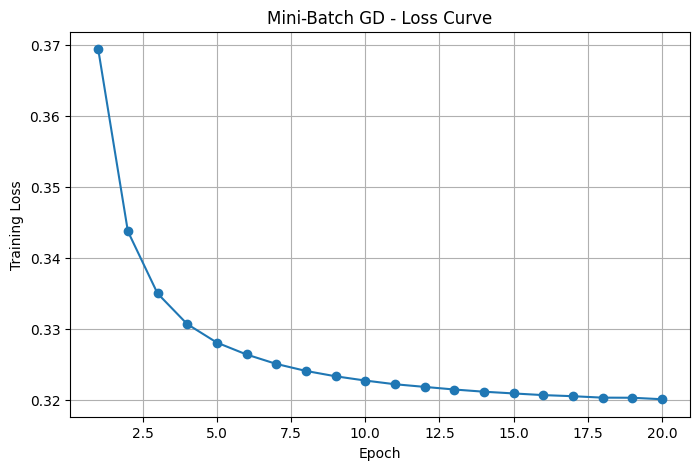

In [6]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))


def bce_loss(X, y, w, b):
    p = np.clip(sigmoid(X @ w + b), 1e-15, 1 - 1e-15)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))


n_samples, n_features = X_train_scaled.shape

weights = np.zeros(n_features)
bias = 0.0

learning_rate = 0.01
epochs = 20
batch_size = 32

rng = np.random.default_rng(42)
loss_history = []

for epoch in range(epochs):

    # Shuffle data each epoch
    indices = rng.permutation(n_samples)

    X_shuffled = X_train_scaled[indices]
    y_shuffled = y_train_np[indices]

    # Divide data into mini-batches
    for start in range(0, n_samples, batch_size):

        end = start + batch_size

        X_batch = X_shuffled[start:end]
        y_batch = y_shuffled[start:end]

        # Predictions for the batch
        p = sigmoid(X_batch @ weights + bias)

        # Calculate errors
        error = p - y_batch

        # Calculate gradients
        dw = X_batch.T @ error / len(y_batch)
        db = np.mean(error)

        # Update weights and bias
        weights -= learning_rate * dw
        bias -= learning_rate * db

    # Calculate loss after each epoch
    loss_history.append(
        bce_loss(X_train_scaled, y_train_np, weights, bias)
    )


# ----- Evaluation on validation data -----

y_prob_gd = sigmoid(X_val_scaled @ weights + bias)
y_pred_gd = (y_prob_gd >= 0.5).astype(int)

gd_res = {
    'Algorithm': 'Mini-Batch GD',
    'Accuracy': accuracy_score(y_val_np, y_pred_gd),
    'Precision': precision_score(y_val_np, y_pred_gd, zero_division=0),
    'Recall': recall_score(y_val_np, y_pred_gd, zero_division=0),
    'F1 Score': f1_score(y_val_np, y_pred_gd, zero_division=0),
    'Loss': log_loss(y_val_np, y_prob_gd, labels=[0, 1]),
}

print("MINI-BATCH GRADIENT DESCENT")

for k, v in gd_res.items():
    print(f"{k:10}: {v if isinstance(v, str) else round(v, 4)}")


# ----- Loss Curve -----

plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), loss_history, marker='o')
plt.title("Mini-Batch GD - Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.grid(True)
plt.show()

##  7. Final Comparison

In [7]:
# ===== Final comparison table =====
results = pd.DataFrame([lr_res, gd_res])
display(results)

,Algorithm,Accuracy,Precision,Recall,F1 Score,Loss
0,LBFGS (sklearn),0.855213,0.738732,0.616709,0.672228,0.316508
1,Mini-Batch GD,0.855366,0.743390,0.609694,0.669937,0.318105
